# Informe de Selección de Modelo — Default of Credit Card Clients

- **Grupo**: [Juan David Ardila Arboleda CC 1017252953 - Lina Isabel Vasquez Villegas CC 1036669649]
- **Variante**: clasificación binaria
- **Conjunto de datos**: Default of Credit Card Clients — UCI Machine Learning Repository
- **Fecha**: 2026-10-07


## 0. Configuración

La celda siguiente importa todas las librerías que utiliza el notebook y fija la semilla aleatoria. Si se ejecuta sin errores, el entorno está listo:

In [8]:
%pip install optuna
%pip install optuna scikit-learn openpyxl matplotlib pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from sklearn.base import BaseEstimator
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, roc_auc_score
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42

## 1. Los datos

### 1.1 Carga del archivo original

La celda siguiente lee el archivo original e imprime su tamaño:

In [10]:
from pathlib import Path

DATA_PATH = Path(r"C:\Users\ASUS\Downloads\default+of+credit+card+clients\default of credit card clients.xlsx")
print(f"Archivo disponible: {DATA_PATH.exists()}")

Archivo disponible: True


In [11]:
assert DATA_PATH.exists(), f"No se encontró el archivo: {DATA_PATH}"

# The workbook contains an auxiliary first row (X1...X23/Y).
# The second row contains the variable names used in the analysis.
raw = pd.read_excel(DATA_PATH, sheet_name="Data", header=1)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")


30,000 rows x 25 columns


Los datos contienen 30.000 filas y 25 columnas. **Cada fila representa un cliente de tarjeta de crédito**. Las variables describen el límite de crédito, información demográfica, estado de pagos, montos facturados y pagos anteriores del cliente. La celda siguiente muestra las primeras filas de los datos originales.

In [12]:
raw.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


La inspección de tipos, valores faltantes y valores distintos permite verificar la estructura de cada variable antes del modelado:

In [13]:
pd.DataFrame(
    {
        "type": raw.dtypes.astype(str),
        "missing": raw.isna().sum(),
        "distinct values": raw.nunique(),
    }
)

,type,missing,distinct values
ID,int64,0,30000
LIMIT_BAL,int64,0,81
SEX,int64,0,2
EDUCATION,int64,0,7
MARRIAGE,int64,0,4
AGE,int64,0,56
PAY_0,int64,0,11
PAY_2,int64,0,11
PAY_3,int64,0,11
PAY_4,int64,0,11


Dos aspectos estructurales son importantes antes del modelado. `ID` es un **identificador**, no un predictor del comportamiento crediticio, por lo que se elimina. `SEX`, `EDUCATION` y `MARRIAGE` están almacenadas como números, pero esos números representan categorías y no magnitudes continuas:

In [14]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"{col}: {sorted(raw[col].unique())}")


SEX: [np.int64(1), np.int64(2)]
EDUCATION: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
MARRIAGE: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


Antes de la división realizamos únicamente ajustes estructurales. Se elimina `ID` porque identifica de forma única cada registro. `SEX`, `EDUCATION` y `MARRIAGE` se convierten a tipo categórico porque sus valores numéricos son etiquetas, no magnitudes. No se realiza imputación, escalamiento ni codificación antes del split.

In [15]:
TARGET = "default payment next month"

data = raw.drop(columns="ID").copy()

categorical_cols = ["SEX", "EDUCATION", "MARRIAGE"]
for col in categorical_cols:
    data[col] = data[col].astype("category")

print(f"{data.shape[0]:,} rows x {data.shape[1]} columns")
print(f"Target: {TARGET}")
print(f"Missing values: {data.isna().sum().sum()}")


30,000 rows x 24 columns
Target: default payment next month
Missing values: 0


Ahora hay 24 columnas: **23 predictores y la variable objetivo**. El archivo fuente no presenta valores faltantes. Las tres variables categóricas permanecen sin codificar en este punto para que la codificación se aprenda únicamente a partir de los datos de entrenamiento dentro del pipeline.

In [16]:
counts = data[TARGET].value_counts().sort_index()
pd.DataFrame({"customers": counts, "share": (counts / len(data)).round(4)})


,customers,share
default payment next month,,
0,23364,0.7788
1,6636,0.2212


La clase `1` es la clase positiva: el cliente incumplió el pago en el mes siguiente. La clase `0` indica que no incumplió. La clase positiva representa **22,12 %** de las 30.000 observaciones, por lo que la clase minoritaria supera el mínimo del 20 %.

In [17]:
predictors = data.drop(columns=TARGET)
n_numeric = predictors.select_dtypes(include="number").shape[1]
n_categorical = predictors.shape[1] - n_numeric
minority_share = data[TARGET].value_counts(normalize=True).min()
n_missing = int(predictors.isna().sum().sum())

requirements = {
    "binary target": data[TARGET].nunique() == 2,
    f"smaller class >= 20% (it is {minority_share:.1%})": minority_share >= 0.20,
    f"at least 1,000 rows (it has {len(data):,})": len(data) >= 1000,
    f"at least 8 predictors (it has {predictors.shape[1]})": predictors.shape[1] >= 8,
    f"numeric and categorical columns ({n_numeric} and {n_categorical})": n_numeric > 0 and n_categorical > 0,
    f"a preprocessing need ({n_missing} missing, {n_categorical} to encode)": n_missing > 0 or n_categorical > 0,
}

for requirement, passed in requirements.items():
    print(f"{'PASS' if passed else 'FAIL'}  {requirement}")

PASS  binary target
PASS  smaller class >= 20% (it is 22.1%)
PASS  at least 1,000 rows (it has 30,000)
PASS  at least 8 predictors (it has 23)
PASS  numeric and categorical columns (20 and 3)
PASS  a preprocessing need (0 missing, 3 to encode)


Todas las comprobaciones se cumplen. Después de los ajustes estructurales hay **20 predictores numéricos y 3 categóricos**. No existen valores faltantes, pero las variables categóricas requieren codificación y, por tanto, existe una necesidad real de preprocesamiento.

✍️ **Entregable 1 de 8 — Ficha del conjunto de datos**

- **Nombre y fuente:** *Default of Credit Card Clients*, UCI Machine Learning Repository.
- **Qué representa una fila:** un cliente de tarjeta de crédito, con información sobre límite de crédito, características demográficas, estado de pagos, montos facturados y pagos previos.
- **Tamaño después de los ajustes estructurales:** 30.000 filas × 24 columnas (23 predictores y la variable objetivo).
- **Variable objetivo:** `default payment next month`. El valor `1` indica que el cliente incumplió el pago en el mes siguiente y `0` que no incumplió. La clase positiva representa el 22,12 % de las observaciones.
- **Decisión que podría apoyar el modelo:** ayudar a un equipo de riesgo crediticio a identificar clientes con mayor riesgo estimado de incumplimiento para priorizar acciones de gestión. El modelo apoya la decisión; no sustituye la decisión crediticia final.
- **Columnas eliminadas antes del modelado:** `ID`, porque identifica cada registro pero no describe el comportamiento crediticio del cliente. No identificamos columnas que registren directamente el resultado futuro; las variables de estado de pago, facturación y pagos describen historial previo al incumplimiento del mes siguiente.
- **Ajustes estructurales antes de la división:** `SEX`, `EDUCATION` y `MARRIAGE` se convirtieron de códigos numéricos a variables categóricas, porque sus valores representan categorías y no cantidades continuas. Eliminar un identificador y corregir tipos de datos no estima parámetros a partir de las observaciones, por lo que no utiliza información del conjunto de prueba.
- **Verificación de requisitos:** todas las condiciones mínimas imprimen `PASS`.


## 2. La métrica

### ¿Por qué ROC AUC?

Nuestro clasificador asignará a cada cliente un **puntaje de riesgo**: un valor que aumenta con el riesgo estimado de incumplir el siguiente pago. Convertir ese puntaje en una decisión final de *marcar / no marcar* exige elegir un umbral operativo. Como el dataset no contiene los costos de negocio necesarios para justificar ese umbral, usamos **ROC AUC** para comparar la capacidad de ordenamiento de los modelos sin fijar todavía un punto de corte.

Un ROC AUC de **0,5** equivale a un ordenamiento al azar y un ROC AUC de **1,0** representa una separación perfecta. La misma métrica se utiliza en el torneo, el tuning y la prueba final.

In [18]:
SCORING = "roc_auc"

✍️ **Entregable 2 de 8 — La métrica**

- **Métrica:** ROC AUC. Usaremos la misma métrica en el torneo de modelos, la optimización de hiperparámetros y la prueba final.
- **Qué significan 0,5 y 1,0:** un ROC AUC de 0,5 indica una capacidad de ordenamiento equivalente al azar. Un ROC AUC de 1,0 representa una separación perfecta entre clientes que incumplen y clientes que no incumplen.
- **Qué significa un umbral:** convertiría el puntaje de riesgo del modelo en una decisión operativa. Por encima del umbral, un cliente podría ser marcado para revisión o acción preventiva.
- **De qué dependería el umbral:** del costo financiero de un incumplimiento, el costo de revisar o contactar a un cliente, la tolerancia a falsos positivos y falsos negativos y la capacidad operativa. Como estos valores no están disponibles en el conjunto de datos, no imponemos un umbral arbitrario durante la selección del modelo.


## 3. División de los datos

### 3.1 Conjunto de prueba reservado

La celda siguiente separa los 23 predictores de la variable objetivo y reserva el 20 % de los 30.000 clientes como conjunto de prueba sin tocar. La estratificación conserva la tasa observada de incumplimiento en ambas particiones:

In [19]:
X = data.drop(columns=TARGET)
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

La celda siguiente comprueba el tamaño de cada partición y la proporción de observaciones positivas:

In [20]:
pd.DataFrame(
    {
        "rows": [len(y_train), len(y_test)],
        "positive share": [y_train.mean(), y_test.mean()],
    },
    index=["training set", "test set"],
).round(4)

,rows,positive share
training set,24000,0.2212
test set,6000,0.2212


El conjunto de entrenamiento contiene **24.000 filas** y el conjunto de prueba **6.000 filas**. Ambos conservan aproximadamente el **22,12 %** de clase positiva (clientes que incumplieron).

**Desde este punto hasta la Sección 7, `X_test` y `y_test` permanecen sin utilizar.**

In [21]:
N_FOLDS = 5
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

La celda siguiente muestra los cinco folds, el número de filas usadas para ajustar cada modelo, el tamaño del fold de validación y su proporción de clase positiva:

In [22]:
fold_rows = []
for fold, (fit_index, validation_index) in enumerate(cv.split(X_train, y_train), start=1):
    fold_rows.append(
        {
            "fold": fold,
            "rows fitted on": len(fit_index),
            "validation rows": len(validation_index),
            "validation positive share": y_train.iloc[validation_index].mean(),
        }
    )

pd.DataFrame(fold_rows).set_index("fold").round(4)

,rows fitted on,validation rows,validation positive share
fold,,,
1,19200,4800,0.2210
2,19200,4800,0.2212
3,19200,4800,0.2212
4,19200,4800,0.2212
5,19200,4800,0.2212


Con validación cruzada de 5 folds sobre las 24.000 filas de entrenamiento, cada modelo se ajusta con aproximadamente **19.200 filas** y se valida con aproximadamente **4.800 filas** por fold. La estratificación mantiene la proporción de clase positiva cercana al 22,12 % en cada partición.

✍️ **Entregable 3 de 8 — La división de los datos**

- **Tamaños:** 24.000 filas para entrenamiento y 6.000 reservadas para la prueba final.
- **Por qué 20 % para prueba:** 6.000 observaciones proporcionan una muestra independiente suficientemente amplia para una evaluación final, mientras el 80 % permanece disponible para entrenamiento y validación cruzada.
- **Validación cruzada:** usamos 5 folds estratificados. En cada fold, el modelo se ajusta aproximadamente con 19.200 filas y se valida con aproximadamente 4.800.
- **Por qué estratificar:** la clase positiva representa aproximadamente el 22,12 %. La estratificación conserva aproximadamente esa proporción en entrenamiento, prueba y cada fold.
- **Regla del conjunto de prueba:** `X_test` y `y_test` permanecen intactos durante el preprocesamiento, la comparación de modelos y el tuning. Se utilizan únicamente en la Sección 7.


## 4. Pipeline de preprocesamiento

### 4.1 Grupos de columnas

En este dataset, `SEX`, `EDUCATION` y `MARRIAGE` son códigos categóricos. Los demás predictores son mediciones numéricas o variables ordenadas del historial de pagos. No hay predictores originales ya codificados como características binarias 0/1:

In [23]:
CATEGORICAL_COLS = ["SEX", "EDUCATION", "MARRIAGE"]
BINARY_COLS = []
NUMERIC_COLS = [
    column for column in X_train.columns
    if column not in CATEGORICAL_COLS + BINARY_COLS
]

print(f"numeric ({len(NUMERIC_COLS)}): {NUMERIC_COLS}")
print(f"binary ({len(BINARY_COLS)}): {BINARY_COLS}")
print(f"categorical ({len(CATEGORICAL_COLS)}): {CATEGORICAL_COLS}")


numeric (20): ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
binary (0): []
categorical (3): ['SEX', 'EDUCATION', 'MARRIAGE']


Una columna que no pertenezca a ningún grupo sería **eliminada sin advertencia**. La siguiente celda verifica que cada predictor pertenezca exactamente a un grupo y detiene el notebook si esto no se cumple:

In [24]:
assigned = NUMERIC_COLS + BINARY_COLS + CATEGORICAL_COLS

assert len(assigned) == len(set(assigned)), "a column is in more than one group"
assert set(assigned) == set(X_train.columns), "a column is in no group, or a name is misspelled"
print(f"all {len(assigned)} predictor columns are in exactly one group")

all 23 predictor columns are in exactly one group


### 4.2 Diagnóstico de variables monetarias (solo entrenamiento)

Antes de decidir sobre transformaciones, examinamos `BILL_AMT1`–`BILL_AMT6` y `PAY_AMT1`–`PAY_AMT6` **exclusivamente en `X_train`**. Se muestran asimetría, percentiles, ceros y valores negativos, además de histogramas. Los montos pueden contener ceros y, en el caso de facturación, valores negativos; por eso `np.log(x)` no es una transformación directa válida para todas las observaciones. La decisión sobre transformación se documenta después de inspeccionar estos resultados, sin utilizar `X_test`.


,asimetria,minimo,p50,p95,p99,maximo,porcentaje_ceros,porcentaje_negativos
BILL_AMT1,2.69,-165580,22330.0,199801.05,348402.41,964511,6.72,1.95
BILL_AMT2,2.73,-69777,21107.0,193244.05,334929.25,983931,8.28,2.17
BILL_AMT3,2.73,-61506,20031.0,186886.00,323101.81,855086,9.62,2.15
BILL_AMT4,2.82,-81334,19004.5,173812.30,304594.51,891586,10.65,2.21
BILL_AMT5,2.92,-81334,18102.5,165512.30,284834.81,927171,11.78,2.18
BILL_AMT6,2.88,-339603,16993.0,161732.90,274502.88,961664,13.43,2.32
PAY_AMT1,15.31,0,2100.5,18094.15,67572.32,873552,17.42,0.00
PAY_AMT2,21.12,0,2014.0,19058.15,77010.79,1215471,18.02,0.00
PAY_AMT3,18.64,0,1805.5,17805.20,70077.15,896040,19.92,0.00
PAY_AMT4,12.38,0,1500.0,16406.40,64760.42,621000,21.42,0.00


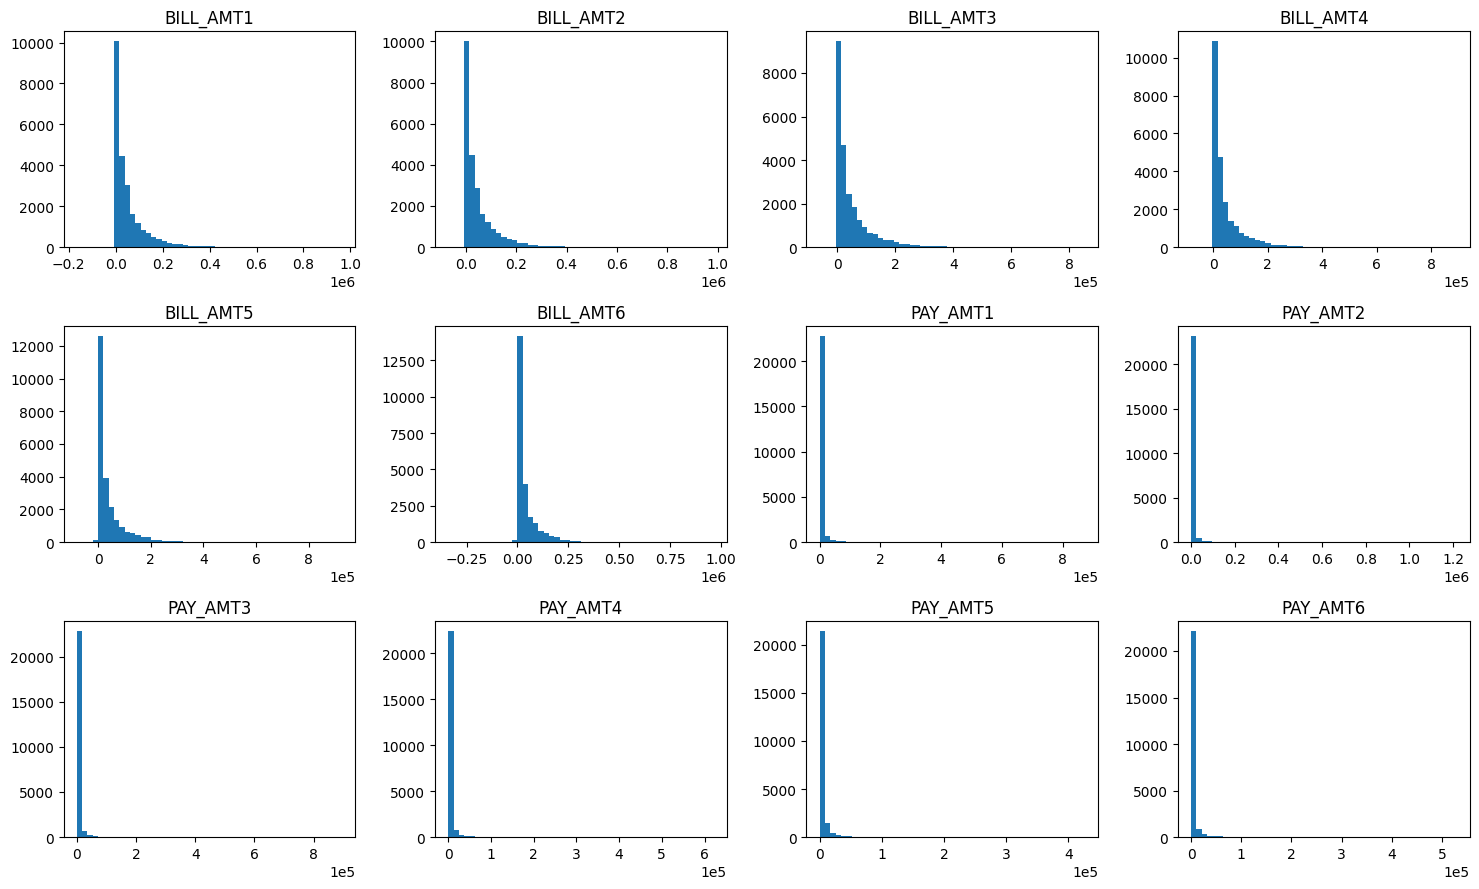

In [25]:
MONEY_COLS = [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]
monetary = X_train[MONEY_COLS]
monetary_summary = pd.DataFrame({
    "asimetria": monetary.skew(),
    "minimo": monetary.min(),
    "p50": monetary.quantile(0.50),
    "p95": monetary.quantile(0.95),
    "p99": monetary.quantile(0.99),
    "maximo": monetary.max(),
    "porcentaje_ceros": monetary.eq(0).mean().mul(100),
    "porcentaje_negativos": monetary.lt(0).mean().mul(100),
})
display(monetary_summary.round(2))
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, column in zip(axes.flat, MONEY_COLS):
    ax.hist(monetary[column].dropna(), bins=50)
    ax.set_title(column)
    ax.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
plt.tight_layout()
plt.show()


### 4.3 Interpretación del diagnóstico y decisión sobre la transformación

En las **24.000 observaciones de entrenamiento**, las seis variables `BILL_AMT` muestran asimetría positiva (aproximadamente **2,69–2,92**), valores negativos (**1,95 %–2,32 %**) y ceros (**6,72 %–13,43 %**). Las seis variables `PAY_AMT` presentan colas derechas todavía más pronunciadas (asimetría **10,55–21,12**) y abundantes ceros (**17,42 %–24,11 %**), sin valores negativos observados. La distancia entre los percentiles 50, 95 y 99 y los máximos respalda la presencia de valores extremos.

**Decisión:** para esta comparación conservamos los montos en su escala original, con imputación por mediana y estandarización dentro del pipeline. No aplicamos `log(x)` directamente porque los ceros y los valores negativos de facturación lo impiden. Existen alternativas válidas (por ejemplo, `log1p` para pagos no negativos o una transformación con signo/Yeo-Johnson para facturación), pero elegir una de ellas requeriría incorporarla **dentro del pipeline** y contrastar su rendimiento por validación cruzada; el diagnóstico descriptivo por sí solo no demuestra que mejore el ROC AUC. Esta es una **decisión metodológica provisional**, no una afirmación de que las distribuciones sean simétricas ni de que la transformación resulte inútil.


### 4.4 Tratamiento de cada grupo

Aplicamos la misma estructura de preprocesamiento a todos los modelos candidatos:

- **Columnas numéricas:** imputación por mediana dentro del pipeline y posterior estandarización. Aunque actualmente no hay valores faltantes, el imputador mantiene el flujo robusto.
- **Columnas categóricas:** imputación por moda y codificación one-hot. Esto evita interpretar los códigos de categoría como magnitudes continuas.
- **Columnas binarias:** no hay predictores originales en este grupo.

Todo el preprocesamiento permanece dentro del pipeline para que, durante la validación cruzada, sus parámetros se aprendan únicamente con la parte de entrenamiento de cada fold.

In [26]:
numeric_steps = Pipeline(
    [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]
)
categorical_steps = Pipeline(
    [
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_steps, NUMERIC_COLS),
        ("binary", "passthrough", BINARY_COLS),
        ("categorical", categorical_steps, CATEGORICAL_COLS),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

La celda siguiente define `make_model`, que une el preprocesador y un modelo dentro de un único pipeline. Todos los modelos de las Secciones 5, 6 y 7 se construyen con esta función, de modo que reciben exactamente el mismo preprocesamiento:

In [27]:
def make_model(estimator: BaseEstimator) -> Pipeline:
    """Join the shared preprocessor and a model into one pipeline.

    Args:
        estimator: Any scikit-learn classifier, not yet fitted.

    Returns:
        A pipeline that prepares the columns and then applies the model.
    """
    return Pipeline([("prep", preprocessor), ("model", estimator)])

La celda siguiente ajusta el preprocesador sobre el conjunto de entrenamiento **solo para inspeccionar su salida**: cuántas columnas recibirán los modelos y cómo se ven después de la transformación:

In [28]:
X_train_preproc = preprocessor.fit_transform(X_train)

print(f"{X_train.shape[1]} columns in, {X_train_preproc.shape[1]} columns out")
X_train_preproc.head(3)

23 columns in, 33 columns out


,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,...,EDUCATION_1,EDUCATION_2,EDUCATION_3,EDUCATION_4,EDUCATION_5,EDUCATION_6,MARRIAGE_0,MARRIAGE_1,MARRIAGE_2,MARRIAGE_3
22788,-0.056866,-0.264558,1.793311,1.780193,2.652046,1.911811,0.240260,0.256087,1.505547,1.745089,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
29006,-0.134081,-0.155804,0.902944,-0.722324,-0.697642,-1.530826,-1.537252,-1.489963,-0.695165,-0.691138,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
16950,-1.215090,1.584260,0.902944,1.780193,0.139780,0.190493,0.240260,0.256087,-0.556800,-0.576836,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


La salida anterior se utiliza únicamente para inspeccionar la transformación. Los 23 predictores originales se convierten en 33 columnas de entrada para los modelos: 20 numéricas estandarizadas y 13 columnas one-hot generadas a partir de las tres variables categóricas. Esta matriz inspeccionada no se utiliza para entrenar ni para la validación cruzada.

✍️ **Entregable 4 de 8 — Tabla de preprocesamiento**

| Grupo | Columnas | Tratamiento, en orden | Justificación |
|---|---|---|---|
| Numéricas | 20 predictores: `LIMIT_BAL`, `AGE`, `PAY_0`, `PAY_2`–`PAY_6`, `BILL_AMT1`–`BILL_AMT6`, `PAY_AMT1`–`PAY_AMT6` | imputación por mediana y luego estandarización | Actualmente no hay faltantes, pero el imputador hace robusto el pipeline. La estandarización evita que escalas muy distintas afecten especialmente a KNN y regresión logística. |
| Binarias | ninguna | ninguno | No existe un predictor original que sea una característica binaria 0/1. |
| Categóricas | `SEX`, `EDUCATION`, `MARRIAGE` | imputación por moda y luego one-hot encoding | Sus números son códigos de categorías, no magnitudes continuas. El one-hot encoding evita imponer distancias artificiales entre categorías. |

- **Valores faltantes:** actualmente hay 0 valores faltantes en los predictores.
- **Columnas:** entran 23 predictores al preprocesador y salen 33 columnas: 20 numéricas estandarizadas y 13 columnas one-hot.
- **Por qué el preprocesamiento está dentro del pipeline:** en cada fold, los parámetros de imputación, escalamiento y codificación se aprenden únicamente con las filas de entrenamiento. Esto evita fuga de información desde validación o prueba.


**Evaluación de la transformación monetaria:** El diagnóstico anterior permite verificar colas largas, ceros y montos negativos en entrenamiento. **Decisión:** mantener los montos en su escala original en este experimento, con imputación mediana y estandarización, para conservar una comparación homogénea entre modelos y no introducir una transformación sin validación adicional. Una alternativa para futuros experimentos es `log1p` solo en montos no negativos, o una transformación con signo como `sign(x)*log1p(abs(x))` para admitir negativos; cualquiera debe integrarse al pipeline y evaluarse mediante CV. No afirmamos que la transformación mejoraría el ROC AUC sin medirlo.


## 5. Torneo de modelos

### 5.1 Candidatos y configuraciones iniciales

Las reglas iniciales para KNN y el árbol de decisión dependen de $n$, el número de filas con las que se ajusta cada modelo dentro de un fold. La celda siguiente calcula $n$ a partir del conjunto de entrenamiento y de los 5 folds:

In [29]:
fit_rows = len(X_train) * (N_FOLDS - 1) // N_FOLDS

k_neighbors = round(np.sqrt(fit_rows))

# If k_neighbors is even -> k_neighbors + 1
if k_neighbors % 2 == 0:
    k_neighbors += 1
    
min_leaf = round(0.01 * fit_rows)

print(f"rows fitted on in one fold (n): {fit_rows:,}")
print(f"KNN: k = sqrt(n), rounded to an odd number -> {k_neighbors}")
print(f"decision tree: maximum depth 5, at least 1% of n per leaf -> {min_leaf} rows")

rows fitted on in one fold (n): 19,200
KNN: k = sqrt(n), rounded to an odd number -> 139
decision tree: maximum depth 5, at least 1% of n per leaf -> 192 rows


Para nuestro conjunto de entrenamiento, las reglas anteriores determinan automáticamente las configuraciones iniciales a partir del número de filas utilizadas en cada fold. No modificamos estos valores después de observar resultados de validación.

`LogisticRegression` y `GradientBoostingClassifier` utilizan las configuraciones iniciales definidas en el torneo.

In [30]:
candidates = {
    "Baseline (most frequent class)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=k_neighbors),
    "Decision tree": DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=min_leaf, random_state=RANDOM_STATE
    ),
    "Gradient boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

### 5.2 Regla de selección

La regla se fija antes de observar cualquier resultado: **el modelo con mayor ROC AUC promedio en validación cruzada pasa al tuning.**

### 5.3 Ejecución del torneo

`cross_val_score` ajusta un pipeline nuevo en cada fold. Esto hace que el preprocesamiento se aprenda solo con los datos de entrenamiento de ese fold y evita fuga de información.

In [31]:
cv_scores = {}
for name, estimator in candidates.items():
    cv_scores[name] = cross_val_score(
        make_model(estimator), X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1
    )

La celda siguiente resume los resultados de los folds en una tabla con la media y la desviación estándar de cada modelo, ordenada de mayor a menor ROC AUC promedio:

In [32]:
tournament = pd.DataFrame.from_dict(
    cv_scores,
    orient="index",
    columns=[f"auc_fold_{i}" for i in range(N_FOLDS)]
)
fold_columns = tournament.columns
tournament["cv_auc_mean"] = tournament[fold_columns].mean(axis=1)
tournament["cv_auc_std"] = tournament[fold_columns].std(axis=1)
tournament = tournament.sort_values("cv_auc_mean", ascending=False)
tournament

,auc_fold_0,auc_fold_1,auc_fold_2,auc_fold_3,auc_fold_4,cv_auc_mean,cv_auc_std
Gradient boosting,0.784912,0.782243,0.771438,0.784144,0.785001,0.781548,0.005759
KNN,0.769589,0.761169,0.743083,0.755022,0.765737,0.758920,0.010385
Decision tree,0.757154,0.760470,0.746618,0.760816,0.769407,0.758893,0.008222
Logistic regression,0.742875,0.729664,0.709604,0.719796,0.733890,0.727166,0.012854
Baseline (most frequent class),0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.000000


La tabla anterior contiene la evidencia del torneo. Todos los candidatos fueron evaluados con los mismos cinco folds estratificados, la misma métrica ROC AUC y el mismo pipeline de preprocesamiento. El modelo con mayor `cv_auc_mean` es el seleccionado para tuning.

In [33]:
WINNER = tournament.index[0]
print(f"model chosen for tuning: {WINNER}")

model chosen for tuning: Gradient boosting


El modelo indicado arriba es el único candidato que pasa a la optimización de hiperparámetros de la Sección 6. `X_test` y `y_test` permanecen sin utilizar.

✍️ **Entregable 5 de 8 — Torneo de modelos**

- **Configuración inicial:** el baseline usa la clase más frecuente. Regresión logística inicia con `C=1.0`; Gradient Boosting con sus valores iniciales de 100 árboles, profundidad 3 y `learning_rate=0.1`. Con 24.000 filas y 5-fold CV, cada ajuste utiliza aproximadamente 19.200 filas. Por ello, KNN inicia con **k=139** y el árbol con `max_depth=5` y al menos **192 filas por hoja**. Estos valores se fijaron antes de observar los resultados.
- **Regla de selección:** pasa a tuning el candidato con mayor ROC AUC promedio en los mismos cinco folds estratificados.
- **Resultado:** Gradient Boosting obtuvo el mayor ROC AUC promedio, **0,7815 ± 0,0058**. KNN obtuvo **0,7589 ± 0,0104**, Decision Tree **0,7589 ± 0,0082** y Logistic Regression **0,7272 ± 0,0129**.
- **Modelo seleccionado:** **Gradient Boosting**, porque alcanzó el mayor ROC AUC promedio bajo la regla definida previamente.
- **Comparación con baseline:** el baseline obtuvo **0,5000 AUC**; todos los modelos entrenados lo superaron.

- **Diferencia frente al segundo lugar y dispersión:** Gradient Boosting (0,7815 ± 0,0058) supera a KNN (0,7589 ± 0,0104) en **0,0226 ROC AUC**. La diferencia es **mayor** que la desviación estándar de cada candidato (0,0058 y 0,0104). Es una ventaja relevante frente a la variabilidad descriptiva entre folds, aunque esta comparación por sí sola no constituye una prueba de significación estadística.


## 6. Optimización del modelo seleccionado

### 6.1 Objetivo

Optuna propone combinaciones de hiperparámetros dentro de los rangos definidos. Cada trial se evalúa con los mismos cinco folds estratificados y con ROC AUC, manteniendo el procedimiento comparable con el torneo.

In [34]:
def objective(trial: optuna.Trial) -> float:
    """Cross-validated AUC of gradient boosting for one set of hyperparameters.

    Args:
        trial: The Optuna trial that proposes the hyperparameter values.

    Returns:
        The mean ROC AUC across the folds of cv on the training set.
    """
    estimator = GradientBoostingClassifier(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.5, log=True),
        n_estimators=trial.suggest_int("n_estimators", 30, 400),
        max_depth=trial.suggest_int("max_depth", 2, 5),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 60),
        random_state=RANDOM_STATE,
    )
    scores = cross_val_score(
        make_model(estimator), X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1
    )
    return scores.mean()

### 6.2 Estudio de Optuna

La celda siguiente crea el estudio, define la dirección de optimización y fija la semilla del sampler para que la búsqueda sea reproducible:

In [35]:
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)

[I 2026-10-14 10:32:09,150] A new study created in memory with name: no-name-b29cc65c-3cce-4381-883c-bde8f0cc4e20


La celda siguiente ejecuta 30 trials; cada trial implica cinco ajustes por la validación cruzada. Optuna muestra una línea a medida que termina cada prueba:

In [36]:
N_TRIALS = 30

study.optimize(objective, n_trials=N_TRIALS)

[I 2026-10-14 10:33:25,972] Trial 0 finished with value: 0.7830213995697276 and parameters: {'learning_rate': 0.043284502212938815, 'n_estimators': 382, 'max_depth': 4, 'subsample': 0.8394633936788146, 'min_samples_leaf': 10}. Best is trial 0 with value: 0.7830213995697276.
[I 2026-10-14 10:33:40,648] Trial 1 finished with value: 0.7776866041295046 and parameters: {'learning_rate': 0.018408992080552525, 'n_estimators': 51, 'max_depth': 5, 'subsample': 0.8404460046972835, 'min_samples_leaf': 43}. Best is trial 0 with value: 0.7830213995697276.
[I 2026-10-14 10:35:45,275] Trial 2 finished with value: 0.7841776079894591 and parameters: {'learning_rate': 0.01083858126934475, 'n_estimators': 389, 'max_depth': 5, 'subsample': 0.6849356442713105, 'min_samples_leaf': 11}. Best is trial 2 with value: 0.7841776079894591.
[I 2026-10-14 10:36:22,873] Trial 3 finished with value: 0.7812563433592231 and parameters: {'learning_rate': 0.020492680115417352, 'n_estimators': 142, 'max_depth': 4, 'subsamp

La celda siguiente muestra el mejor ROC AUC, el trial que lo alcanzó y sus hiperparámetros:

In [37]:
print(f"best CV AUC: {study.best_value:.4f} (trial {study.best_trial.number})")
pd.DataFrame([study.best_params])

best CV AUC: 0.7850 (trial 17)


,learning_rate,n_estimators,max_depth,subsample,min_samples_leaf
0,0.034161,263,5,0.646223,26


In [38]:
SEARCH_RANGES = {
    "learning_rate": (0.01, 0.5),
    "n_estimators": (30, 400),
    "max_depth": (2, 5),
    "subsample": (0.6, 1.0),
    "min_samples_leaf": (1, 60),
}
edge_params = {
    name: value for name, value in study.best_params.items()
    if value == SEARCH_RANGES[name][0] or value == SEARCH_RANGES[name][1]
}
print("best parameters at a search edge:", edge_params if edge_params else "none")


best parameters at a search edge: {'max_depth': 5}


Después de ejecutar el estudio, el mejor resultado y los hiperparámetros anteriores se utilizan para revisar si algún valor quedó en el límite del rango de búsqueda. Un valor óptimo exactamente en un límite sugiere que, en un análisis posterior, podría ser útil ampliar ese rango; no demuestra por sí solo que un valor exterior sea mejor.

### 6.3 Modelo optimizado frente al modelo inicial

La celda siguiente construye Gradient Boosting con los mejores parámetros y vuelve a evaluarlo sobre los mismos folds, comparándolo con la versión sin tuning del torneo:

In [39]:
tuned_model = make_model(
    GradientBoostingClassifier(**study.best_params, random_state=RANDOM_STATE)
)
tuned_scores = cross_val_score(
    tuned_model, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1
)

pd.DataFrame(
    {
        "cv_auc_mean": [tournament.loc[WINNER, "cv_auc_mean"], tuned_scores.mean()],
        "cv_auc_std": [tournament.loc[WINNER, "cv_auc_std"], tuned_scores.std(ddof=1)],
    },
    index=["untuned (Section 5)", "tuned (Section 6)"],
).round(4)

,cv_auc_mean,cv_auc_std
untuned (Section 5),0.7815,0.0058
tuned (Section 6),0.7850,0.0058


In [40]:
untuned_mean = tournament.loc[WINNER, "cv_auc_mean"]
tuned_mean = tuned_scores.mean()
print(f"untuned mean CV AUC: {untuned_mean:.4f}")
print(f"tuned mean CV AUC:   {tuned_mean:.4f}")
print(f"tuning gain:         {tuned_mean - untuned_mean:+.4f}")


untuned mean CV AUC: 0.7815
tuned mean CV AUC:   0.7850
tuning gain:         +0.0035


La comparación anterior utiliza los mismos cinco folds estratificados y la misma métrica ROC AUC del torneo. La diferencia entre el ROC AUC promedio del modelo optimizado y el inicial representa la ganancia del tuning; `X_test` y `y_test` todavía no se utilizan.

✍️ **Entregable 6 de 8 — Optimización de hiperparámetros**

- **Objetivo:** optimizamos únicamente al ganador del torneo, Gradient Boosting, manteniendo el mismo pipeline, los mismos cinco folds estratificados y ROC AUC.
- **Búsqueda:** Optuna ejecutó **30 trials** con `RANDOM_STATE = 42`. El mejor fue el **trial 17**, con ROC AUC promedio de **0,7850**.
- **Mejores hiperparámetros:** `learning_rate=0.034161`, `n_estimators=263`, `max_depth=5`, `subsample=0.646223` y `min_samples_leaf=26`.
- **Revisión de límites:** `max_depth=5` quedó exactamente en el límite superior del rango de búsqueda. Esto sugiere que, en un estudio posterior, sería razonable ampliar ese límite y comprobar si existe una configuración mejor; no asumimos que valores mayores necesariamente mejoren el modelo.
- **Comparación antes/después:** el Gradient Boosting sin tuning obtuvo **0,7815** de ROC AUC promedio y el optimizado **0,7850**, una mejora de **+0,0035**. El conjunto de prueba permaneció intacto durante todo este proceso.


**Rangos de búsqueda, escala y justificación (30 trials; datos de entrenamiento de 24.000 registros):**

| Hiperparámetro | Rango | Escala | Justificación |
|---|---|---|---|
| `learning_rate` | 0,01–0,5 | Logarítmica continua | Explora pasos de aprendizaje pequeños y moderados, con mayor resolución relativa en valores bajos; se combina con el número de árboles. |
| `n_estimators` | 30–400 | Entera uniforme | Contrasta ensambles breves con otros más largos sin disparar excesivamente el costo de 5 folds por trial. |
| `max_depth` | 2–5 | Entera uniforme | Contrasta interacciones relativamente simples y más complejas, moderando sobreajuste con 19.200 registros aproximadamente por ajuste de CV. |
| `subsample` | 0,6–1,0 | Continua uniforme | Evalúa el uso de 60 % a 100 % de las filas en cada etapa, para contrastar regularización estocástica frente a usar todas las observaciones. |
| `min_samples_leaf` | 1–60 | Entera uniforme | Evalúa desde hojas pequeñas hasta hojas con más soporte, para regularizar la complejidad con el tamaño disponible de entrenamiento. |

**Ganancia frente a dispersión:** el ajuste pasa de 0,7815 a 0,7850, es decir, **+0,0035**. Esta ganancia es **menor** que la desviación estándar entre folds del modelo inicial (**0,0058**) y la del modelo ajustado (aproximadamente **0,0058**, según la tabla anterior). Por ello la mejora observada es modesta frente a la dispersión y no permite asegurar una superioridad robusta. La comparación comparte folds, pero no sustituye un análisis de diferencias pareadas ni una evaluación externa adicional.


## 7. Prueba final

La celda siguiente vuelve a ajustar el modelo optimizado con todo el conjunto de entrenamiento, lo evalúa una sola vez sobre el conjunto de prueba y muestra el resultado junto con la estimación obtenida por validación cruzada:

In [41]:
final_model = tuned_model.fit(X_train, y_train)
test_scores = final_model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_scores)

print("ROC AUC of the final model")
print(f"CV mean estimate: {tuned_scores.mean():.4f}")
print(f"CV spread: {tuned_scores.std(ddof=1):.4f}")
print(f"test set: {test_auc:.4f}")

ROC AUC of the final model
CV mean estimate: 0.7850
CV spread: 0.0058
test set: 0.7784


El modelo final obtiene **0,7784** de ROC AUC en el conjunto de prueba, frente a una estimación de **0,7850** en validación cruzada, con una dispersión entre folds de **0,0058**.

### Curva ROC

Cada punto de la **curva ROC** corresponde a un umbral diferente. La curva relaciona la proporción de clientes que realmente incumplen y son detectados (tasa de verdaderos positivos) con la proporción de clientes que no incumplen pero son marcados por error (tasa de falsos positivos). El AUC resume el área bajo esta curva; la diagonal representa un ordenamiento equivalente al azar, con AUC de 0,5.

La siguiente celda muestra la curva ROC del modelo final sobre el conjunto de prueba:


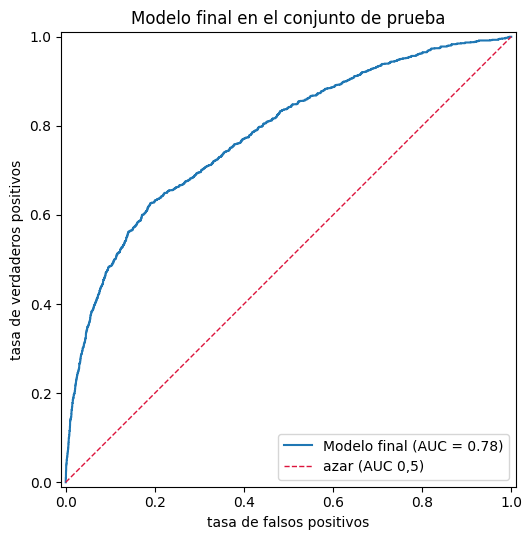

In [42]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
RocCurveDisplay.from_predictions(y_test, test_scores, name="Modelo final", ax=ax)
ax.plot([0, 1], [0, 1], color="crimson", linestyle="--", linewidth=1, label="azar (AUC 0,5)")
ax.set_xlabel("tasa de falsos positivos")
ax.set_ylabel("tasa de verdaderos positivos")
ax.set_title("Modelo final en el conjunto de prueba")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()


La curva muestra la capacidad del modelo para separar clientes que incumplen de los que no incumplen a través de distintos umbrales. Elegir un punto específico de la curva equivale a escoger un umbral operativo; esa decisión debe depender de costos, capacidad y tolerancia al riesgo del negocio, por lo que no se fija arbitrariamente en este notebook.


✍️ **Entregable 7 de 8 — Prueba final**

- **Modelo final:** Gradient Boosting optimizado con `learning_rate=0.034161`, `n_estimators=263`, `max_depth=5`, `subsample=0.646223` y `min_samples_leaf=26`, ajustado nuevamente sobre todo el conjunto de entrenamiento con el pipeline de preprocesamiento.
- **Resultado en prueba:** ROC AUC de **0,7784**, frente a una estimación de validación cruzada de **0,7850** con dispersión de **0,0058**.
- **Interpretación de la diferencia:** el test quedó **0,0066** por debajo del promedio de validación cruzada. La diferencia es apenas mayor que una dispersión de fold (0,0058) y sigue siendo pequeña en términos absolutos, por lo que el desempeño de prueba es cercano al observado durante el desarrollo. No interpretamos esta única diferencia como evidencia suficiente de un problema por sí sola.
- **Uso del conjunto de prueba:** `X_test` y `y_test` se reservaron desde la Sección 3 y se utilizaron para evaluar el modelo únicamente en esta sección, después de finalizar la selección y el tuning. No se modificó el modelo como respuesta al resultado de prueba.


## 8. Conclusiones

✍️ **Entregable 8 de 8 — Conclusiones**

- **Recomendación:** utilizar el Gradient Boosting optimizado como herramienta de apoyo para **ordenar a los clientes según su riesgo estimado de incumplimiento** y ayudar al equipo de riesgo crediticio a priorizar revisiones o acciones preventivas. El modelo no sustituye la decisión crediticia final.
- **Qué esperar en datos nuevos:** en el conjunto de prueba, que no participó en la selección ni en el tuning, el modelo obtuvo un **ROC AUC de 0,7784**. En términos intuitivos, al comparar al azar un cliente que incumple con uno que no incumple, el modelo asigna un puntaje de riesgo mayor al cliente que incumple aproximadamente el **77,8 % de las veces**.
- **Limitaciones:** (1) el torneo comparó las familias con configuraciones iniciales y solamente Gradient Boosting fue optimizado; por ello no podemos afirmar que sea superior a versiones también optimizadas de los demás modelos. (2) Los datos corresponden a clientes de tarjetas de crédito de Taiwán y a un periodo histórico, por lo que el desempeño no debe asumirse automáticamente para clientes actuales o para otros países. (3) El modelo genera un ranking de riesgo, pero el dataset no proporciona los costos y restricciones operativas necesarios para definir un umbral de intervención. (4) Variables demográficas como `SEX`, `EDUCATION` y `MARRIAGE` requieren una revisión adicional de equidad, gobernanza y normativa antes de cualquier uso crediticio real.
- **Siguiente paso:** ampliar el rango de `max_depth`, porque el mejor valor quedó en el límite superior de la búsqueda, y comparar nuevamente mediante validación cruzada. Antes de un uso operativo también sería necesario definir con el negocio los costos de falsos positivos y falsos negativos para seleccionar un umbral, y evaluar estabilidad, interpretabilidad y posibles diferencias de desempeño entre grupos.
